In [7]:
# 匯入 TensorFlow 的 Keras 模組
from tensorflow import keras

# 匯入 Sequential：建立依序排列的神經網路模型
from keras.models import Sequential

# 匯入 Dense：建立全連接層
# 匯入 Flatten：將多維資料展平成一維資料
from keras.layers import Dense, Flatten

In [9]:
# ==============================
# 1. 載入 MNIST 手寫數字資料集
# ==============================

# 指定使用 Keras 內建的 MNIST 資料集
# MNIST 包含 0～9 的手寫數字圖片
mnist = keras.datasets.mnist

# 載入資料集並分成訓練資料與測試資料
# train_data：訓練圖片，共 60,000 張
# train_label：訓練圖片對應的正確數字標籤
# test_data：測試圖片，共 10,000 張
# test_label：測試圖片對應的正確數字標籤
(train_data, train_label), (test_data, test_label) = mnist.load_data()

In [10]:
# ==============================
# 2. 查看 MNIST 資料集的型態與大小
# ==============================

# 查看訓練圖片的資料型態
print(type(train_data))

# 查看訓練圖片的形狀
# (60000, 28, 28) 表示 60,000 張圖片，每張圖片為 28 × 28 像素
print(train_data.shape)

# 查看訓練標籤的資料型態
print(type(train_label))

# 查看訓練標籤的形狀
# (60000,) 表示有 60,000 個標籤
print(train_label.shape)

# 查看測試圖片的形狀
# (10000, 28, 28) 表示 10,000 張測試圖片
print(test_data.shape)

# 查看測試標籤的形狀
# (10000,) 表示有 10,000 個測試標籤
print(test_label.shape)

<class 'numpy.ndarray'>
(60000, 28, 28)
<class 'numpy.ndarray'>
(60000,)
(10000, 28, 28)
(10000,)


In [11]:
# ==============================
# 3. 查看第一筆訓練資料
# ==============================

# 印出第一張圖片的正確標籤（手寫數字）
print(train_label[0])

# 印出第一張圖片的像素矩陣（28 × 28）
# 每個數字代表該像素的灰階值，範圍為 0～255
print(train_data[0])

5
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   0  18 219 253 253 253 253 253 198 

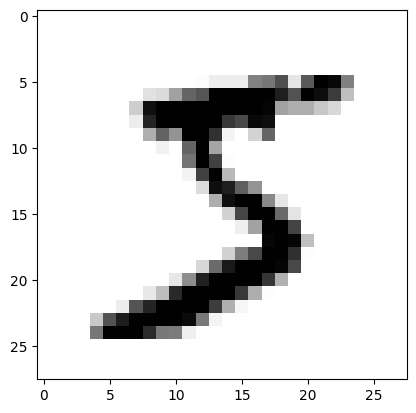

In [12]:
# ==============================
# 4. 顯示第一張 MNIST 手寫數字圖片
# ==============================

import matplotlib.pyplot as plt

# 顯示第一張訓練圖片
# train_data[0]：取出第一張 28 × 28 的圖片
# cmap='binary'：使用黑白色階顯示圖片
plt.imshow(train_data[0], cmap='binary')

# 顯示圖片
plt.show()

In [13]:
# ==============================
# 5. 建立神經網路模型
# ==============================

# 建立 Sequential 順序模型
model = Sequential()

# 將 28 × 28 的圖片攤平成一維資料
# 每張圖片會變成 784 個數值
model.add(Flatten())

# 【已修改】建立隱藏層，原本 32 個神經元改為 64 個
# activation='relu'：使用 ReLU 激活函數
model.add(Dense(64, activation='relu', input_dim=784))

# 建立輸出層，10 個神經元代表數字 0～9
# 【已修改】使用 softmax，輸出各數字的預測機率
model.add(Dense(10, activation='softmax'))

# 編譯模型
# 【已修改】optimizer：rmsprop 改為 adam
# loss：使用稀疏分類交叉熵，適合整數類別標籤
# metrics：使用 accuracy 計算預測準確率
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [14]:
# ==============================
# 6. 訓練神經網路模型
# ==============================

# 使用訓練資料訓練模型
# train_data：訓練圖片
# train_label：訓練圖片的正確答案
# 【已修改】epochs：原本 20 改為 25，代表訓練 25 回合
# 【已修改】batch_size：原本 512 改為 256，每次使用 256 筆資料進行訓練
model.fit(
    train_data,
    train_label,
    epochs=25,
    batch_size=256
)


# ==============================
# 7. 評估模型
# ==============================

# 使用測試資料評估模型的表現
# test_data：測試圖片
# test_label：測試圖片的正確答案
score = model.evaluate(test_data, test_label)

# 印出模型的準確率
# score[1] 代表 accuracy（準確率）
print("測試資料準確率：", score[1])

Epoch 1/25
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8138 - loss: 7.2655 
Epoch 2/25
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8793 - loss: 1.3289
Epoch 3/25
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8878 - loss: 0.6488
Epoch 4/25
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9102 - loss: 0.4325
Epoch 5/25
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9230 - loss: 0.3348
Epoch 6/25
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9327 - loss: 0.2752
Epoch 7/25
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9396 - loss: 0.2356
Epoch 8/25
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9462 - loss: 0.2022
Epoch 9/25
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9498 - loss: 0.1846
Epoch 10/25
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9537 - loss: 0.1634
Epoch 11/25
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9563 - loss: 0.1532
Epoch 12/25
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/ste